In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mahdavi1202/skin-cancer/metadata.csv
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_492_937_958.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_13_21_350.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_456_887_499.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_15_1001_749.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_456_888_961.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_158_621_68.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_48_74_309.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_88_133_64.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_460_893_307.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1/PAT_386_1554_455.png
/kaggle/input/datasets/mahdavi1202/s

In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    for filename in filenames[:5]:
        print("  -", filename)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mahdavi1202
/kaggle/input/datasets/mahdavi1202/skin-cancer
  - metadata.csv
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1
  - PAT_492_937_958.png
  - PAT_13_21_350.png
  - PAT_456_887_499.png
  - PAT_15_1001_749.png
  - PAT_456_888_961.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_3
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_3/imgs_part_3
  - PAT_1726_3228_674.png
  - PAT_1913_3815_367.png
  - PAT_1479_1669_376.png
  - PAT_1449_1554_932.png
  - PAT_1583_2607_628.png
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_2
/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_2/imgs_part_2
  - PAT_650_3858_329.png
  - PAT_766_1444_52.png
  - PAT_806_1520_60.png
  - PAT_677_1350_358.png
  - PAT_856_1626_630.png


In [3]:
import pandas as pd

csv_path = '/kaggle/input/datasets/mahdavi1202/skin-cancer/metadata.csv'
df = pd.read_csv(csv_path)

image_folders = [
    '/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_1/imgs_part_1',
    '/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_2/imgs_part_2',
    '/kaggle/input/datasets/mahdavi1202/skin-cancer/imgs_part_3/imgs_part_3',
]

print("Total rows:", len(df))
print(df['diagnostic'].value_counts())

Total rows: 2298
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

df_clean = df[(df['biopsed'] == True) & (df['gender'].notnull())].copy()

symptom_cols = ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']
for col in symptom_cols:
    df_clean[col] = df_clean[col].astype(str)

df_clean = df_clean.reset_index(drop=True)

# ---- STRATIFIED GROUP K-FOLD SPLIT (patient-safe AND class-balanced) ----
sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(df_clean, df_clean['diagnostic'], groups=df_clean['patient_id']))
trainval_df = df_clean.iloc[trainval_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf2.split(trainval_df, trainval_df['diagnostic'], groups=trainval_df['patient_id']))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

# Verify zero patient overlap (critical check)
print("Overlap train-val:", len(set(train_df['patient_id']) & set(val_df['patient_id'])))
print("Overlap train-test:", len(set(train_df['patient_id']) & set(test_df['patient_id'])))
print("Overlap val-test:", len(set(val_df['patient_id']) & set(test_df['patient_id'])))

print("\nTrain:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))
print("Unique patients — Train:", train_df['patient_id'].nunique(), "Val:", val_df['patient_id'].nunique(), "Test:", test_df['patient_id'].nunique())

print("\nTrain label counts:")
print(train_df['diagnostic'].value_counts())
print("\nVal label counts:")
print(val_df['diagnostic'].value_counts())
print("\nTest label counts:")
print(test_df['diagnostic'].value_counts())
# ---- END SPLIT ----

cat_cols = ['gender', 'smoke', 'drink', 'pesticide', 'skin_cancer_history', 'cancer_history',
            'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region',
            'background_father', 'background_mother']
numeric_cols = ['age', 'fitspatrick', 'diameter_1', 'diameter_2']

def encode_metadata(df, cat_cols, numeric_cols, reference_columns=None):
    df_cat = pd.get_dummies(df[cat_cols].astype(str))
    df_num = df[numeric_cols].fillna(df[numeric_cols].median())
    df_encoded = pd.concat([df_num, df_cat], axis=1)
    if reference_columns is not None:
        df_encoded = df_encoded.reindex(columns=reference_columns, fill_value=0)
    return df_encoded

train_meta = encode_metadata(train_df, cat_cols, numeric_cols)
val_meta = encode_metadata(val_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)
test_meta = encode_metadata(test_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)

le = LabelEncoder()
le.fit(train_df['diagnostic'])
train_labels = le.transform(train_df['diagnostic'])
val_labels = le.transform(val_df['diagnostic'])
test_labels = le.transform(test_df['diagnostic'])

print("\nFeature count:", train_meta.shape[1])
print("Classes:", le.classes_)

Overlap train-val: 0
Overlap train-test: 0
Overlap val-test: 0

Train: 967 Val: 207 Test: 168
Unique patients — Train: 559 Val: 114 Test: 110

Train label counts:
diagnostic
BCC    621
SCC    138
ACK    124
NEV     42
MEL     34
SEK      8
Name: count, dtype: int64

Val label counts:
diagnostic
BCC    132
SCC     36
ACK     20
NEV      9
MEL      7
SEK      3
Name: count, dtype: int64

Test label counts:
diagnostic
BCC    92
ACK    34
SCC    18
MEL    11
NEV     9
SEK     4
Name: count, dtype: int64

Feature count: 68
Classes: ['ACK' 'BCC' 'MEL' 'NEV' 'SCC' 'SEK']


In [5]:
META_DIM = train_meta.shape[1]
print("META_DIM:", META_DIM)

META_DIM: 68


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image
from torchvision import transforms
import torchvision.models as models
import os
import numpy as np

class SkinFusionDataset(Dataset):
    def __init__(self, df, meta_features, labels, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.meta_features = meta_features.reset_index(drop=True)
        self.labels = labels
        self.transform = transform
        self.image_lookup = {}
        for folder in image_folders:
            for fname in os.listdir(folder):
                self.image_lookup[fname] = os.path.join(folder, fname)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'img_id']
        img_path = self.image_lookup[img_name]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        meta = torch.tensor(self.meta_features.iloc[idx].values.astype('float32'))
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, meta, label

transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = SkinFusionDataset(train_df, train_meta, train_labels, image_folders, train_transform)
val_dataset = SkinFusionDataset(val_df, val_meta, val_labels, image_folders, transform)
test_dataset = SkinFusionDataset(test_df, test_meta, test_labels, image_folders, transform)

class_sample_counts = np.array([sum(train_labels == i) for i in range(6)])
sample_weights = 1.0 / class_sample_counts[train_labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class FusionModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(512+32, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        meta_feat = self.meta_branch(meta)
        return self.classifier(torch.cat([img_feat, meta_feat], dim=1))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, metas)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images, metas)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

class_weights = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss()
model = FusionModel(meta_input_dim=META_DIM, num_classes=6).to(device)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(20):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc); history['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/20 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_model.pth')
        print("  -> Saved new best model")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s] 


Epoch 1/20 - Train loss: 1.7808, Train acc: 0.2099 - Val loss: 1.8016, Val acc: 0.1111
  -> Saved new best model
Epoch 2/20 - Train loss: 1.7241, Train acc: 0.2585 - Val loss: 1.6915, Val acc: 0.2705
  -> Saved new best model
Epoch 3/20 - Train loss: 1.6770, Train acc: 0.3237 - Val loss: 1.6728, Val acc: 0.3671
  -> Saved new best model
Epoch 4/20 - Train loss: 1.6345, Train acc: 0.3681 - Val loss: 1.6376, Val acc: 0.3188
Epoch 5/20 - Train loss: 1.5834, Train acc: 0.3702 - Val loss: 1.6537, Val acc: 0.2512
Epoch 6/20 - Train loss: 1.5572, Train acc: 0.4147 - Val loss: 1.5591, Val acc: 0.4251
  -> Saved new best model
Epoch 7/20 - Train loss: 1.4639, Train acc: 0.4705 - Val loss: 1.4745, Val acc: 0.5121
  -> Saved new best model
Epoch 8/20 - Train loss: 1.4383, Train acc: 0.4643 - Val loss: 1.5603, Val acc: 0.2850
Epoch 9/20 - Train loss: 1.3778, Train acc: 0.5119 - Val loss: 1.4738, Val acc: 0.4106
Epoch 10/20 - Train loss: 1.3537, Train acc: 0.5088 - Val loss: 1.4749, Val acc: 0.3768

In [8]:
model.load_state_dict(torch.load('/kaggle/working/best_model.pth'))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

Test loss: 1.4717, Test acc: 0.5298


In [9]:
class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta=None):
        return self.classifier(self.image_branch(image).flatten(1))

img_model = ImageOnlyModel(num_classes=6).to(device)
img_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(img_model, train_loader, criterion, img_optimizer, device)
    val_loss, val_acc = evaluate(img_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model.state_dict(), '/kaggle/working/best_image_only.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.7946, Train acc: 0.2058 - Val loss: 1.7971, Val acc: 0.1836
  -> Saved new best model
Epoch 2/15 - Train loss: 1.7344, Train acc: 0.2606 - Val loss: 1.6580, Val acc: 0.3575
  -> Saved new best model
Epoch 3/15 - Train loss: 1.6986, Train acc: 0.3164 - Val loss: 1.6726, Val acc: 0.3865
  -> Saved new best model
Epoch 4/15 - Train loss: 1.6434, Train acc: 0.3692 - Val loss: 1.6119, Val acc: 0.4106
  -> Saved new best model
Epoch 5/15 - Train loss: 1.6124, Train acc: 0.3702 - Val loss: 1.6175, Val acc: 0.3237
Epoch 6/15 - Train loss: 1.5511, Train acc: 0.4240 - Val loss: 1.5741, Val acc: 0.3913
Epoch 7/15 - Train loss: 1.5240, Train acc: 0.4467 - Val loss: 1.5565, Val acc: 0.4251
  -> Saved new best model
Epoch 8/15 - Train loss: 1.4981, Train acc: 0.4457 - Val loss: 1.5064, Val acc: 0.4348
  -> Saved new best model
Epoch 9/15 - Train loss: 1.4576, Train acc: 0.4747 - Val loss: 1.5449, Val acc: 0.3575
Epoch 10/15 - Train loss: 1.4443, Train acc: 0.4467 - Val los

In [10]:
img_model.load_state_dict(torch.load('/kaggle/working/best_image_only.pth'))
test_loss, test_acc = evaluate(img_model, test_loader, criterion, device)
print(f"Image-only Test acc: {test_acc:.4f}")

Image-only Test acc: 0.5119


In [11]:
class MetaOnlyModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, num_classes))
    def forward(self, image, meta):
        return self.classifier(self.meta_branch(meta))

meta_model = MetaOnlyModel(meta_input_dim=META_DIM, num_classes=6).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/kaggle/working/best_meta_only.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.8224, Train acc: 0.1706 - Val loss: 1.8616, Val acc: 0.0966
  -> Saved new best model
Epoch 2/15 - Train loss: 1.8053, Train acc: 0.1655 - Val loss: 1.8670, Val acc: 0.0966
Epoch 3/15 - Train loss: 1.7820, Train acc: 0.1892 - Val loss: 1.8459, Val acc: 0.0966
Epoch 4/15 - Train loss: 1.7764, Train acc: 0.2027 - Val loss: 1.8382, Val acc: 0.0966
Epoch 5/15 - Train loss: 1.7702, Train acc: 0.1913 - Val loss: 1.8238, Val acc: 0.0870
Epoch 6/15 - Train loss: 1.7465, Train acc: 0.2172 - Val loss: 1.8158, Val acc: 0.0725
Epoch 7/15 - Train loss: 1.7529, Train acc: 0.2213 - Val loss: 1.8192, Val acc: 0.0725
Epoch 8/15 - Train loss: 1.7461, Train acc: 0.2378 - Val loss: 1.8161, Val acc: 0.0725
Epoch 9/15 - Train loss: 1.7058, Train acc: 0.2968 - Val loss: 1.7880, Val acc: 0.0386
Epoch 10/15 - Train loss: 1.7038, Train acc: 0.3351 - Val loss: 1.7816, Val acc: 0.0676
Epoch 11/15 - Train loss: 1.7151, Train acc: 0.3009 - Val loss: 1.8177, Val acc: 0.0483
Epoch 12/15 - T

In [12]:
torch.manual_seed(42)
np.random.seed(42)

meta_model = MetaOnlyModel(meta_input_dim=META_DIM, num_classes=6).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/kaggle/working/best_meta_only.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.8490, Train acc: 0.1799 - Val loss: 1.8990, Val acc: 0.0145
  -> Saved new best model
Epoch 2/15 - Train loss: 1.8013, Train acc: 0.1965 - Val loss: 1.8924, Val acc: 0.0145
Epoch 3/15 - Train loss: 1.7854, Train acc: 0.2006 - Val loss: 1.8572, Val acc: 0.0145
Epoch 4/15 - Train loss: 1.7710, Train acc: 0.2006 - Val loss: 1.8676, Val acc: 0.0145
Epoch 5/15 - Train loss: 1.7705, Train acc: 0.2089 - Val loss: 1.8370, Val acc: 0.0145
Epoch 6/15 - Train loss: 1.7580, Train acc: 0.2461 - Val loss: 1.8079, Val acc: 0.0193
  -> Saved new best model
Epoch 7/15 - Train loss: 1.7679, Train acc: 0.2265 - Val loss: 1.7972, Val acc: 0.0290
  -> Saved new best model
Epoch 8/15 - Train loss: 1.7516, Train acc: 0.2358 - Val loss: 1.7858, Val acc: 0.0435
  -> Saved new best model
Epoch 9/15 - Train loss: 1.7397, Train acc: 0.2554 - Val loss: 1.7994, Val acc: 0.0242
Epoch 10/15 - Train loss: 1.7430, Train acc: 0.2492 - Val loss: 1.8013, Val acc: 0.0435
Epoch 11/15 - Train loss:

In [13]:
meta_model.load_state_dict(torch.load('/kaggle/working/best_meta_only.pth'))
test_loss, test_acc = evaluate(meta_model, test_loader, criterion, device)
print(f"Meta-only Test acc: {test_acc:.4f}")

Meta-only Test acc: 0.1012


In [14]:
def check_predictions(model, loader, device, class_names):
    model.eval()
    all_preds = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            outputs = model(images, metas)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
    unique, counts = np.unique(all_preds, return_counts=True)
    for u, c in zip(unique, counts):
        print(f"  {class_names[u]}: predicted {c} times")

print("Image-only model predictions on test set:")
check_predictions(img_model, test_loader, device, le.classes_)

print("\nMeta-only model predictions on test set:")
check_predictions(meta_model, test_loader, device, le.classes_)

Image-only model predictions on test set:
  ACK: predicted 34 times
  BCC: predicted 84 times
  MEL: predicted 5 times
  NEV: predicted 14 times
  SCC: predicted 13 times
  SEK: predicted 18 times

Meta-only model predictions on test set:
  MEL: predicted 27 times
  SCC: predicted 69 times
  SEK: predicted 72 times


In [15]:
from sklearn.metrics import classification_report

all_preds, all_labels = [], []
meta_model.eval()
with torch.no_grad():
    for images, metas, labels in test_loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        outputs = meta_model(images, metas)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_, zero_division=0))

              precision    recall  f1-score   support

         ACK       0.00      0.00      0.00        34
         BCC       0.00      0.00      0.00        92
         MEL       0.26      0.64      0.37        11
         NEV       0.00      0.00      0.00         9
         SCC       0.09      0.33      0.14        18
         SEK       0.06      1.00      0.11         4

    accuracy                           0.10       168
   macro avg       0.07      0.33      0.10       168
weighted avg       0.03      0.10      0.04       168



In [16]:
model.load_state_dict(torch.load('/kaggle/working/best_model.pth'))
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for images, metas, labels in test_loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        outputs = model(images, metas)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_, zero_division=0))

              precision    recall  f1-score   support

         ACK       0.32      0.24      0.27        34
         BCC       0.69      0.76      0.72        92
         MEL       0.56      0.45      0.50        11
         NEV       0.40      0.44      0.42         9
         SCC       0.00      0.00      0.00        18
         SEK       0.13      0.50      0.21         4

    accuracy                           0.53       168
   macro avg       0.35      0.40      0.35       168
weighted avg       0.50      0.53      0.51       168



In [17]:
class MetaBlock(nn.Module):
    def __init__(self, image_feat_dim, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.meta_gate = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Sigmoid())
        self.meta_bias = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Tanh())
        self.classifier = nn.Sequential(nn.Linear(image_feat_dim, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        gate = self.meta_gate(meta)
        bias = self.meta_bias(meta)
        return self.classifier(img_feat * gate + bias)

metablock_model = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=6).to(device)
metablock_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_model.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(20):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/20 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/kaggle/working/best_metablock.pth')
        print("  -> Saved new best model")

Epoch 1/20 - Train loss: 1.7628, Train acc: 0.2037 - Val loss: 1.7024, Val acc: 0.4155
  -> Saved new best model
Epoch 2/20 - Train loss: 1.7149, Train acc: 0.2802 - Val loss: 1.6994, Val acc: 0.3237
Epoch 3/20 - Train loss: 1.6353, Train acc: 0.3516 - Val loss: 1.6267, Val acc: 0.4058
Epoch 4/20 - Train loss: 1.5914, Train acc: 0.4074 - Val loss: 1.5993, Val acc: 0.4203
  -> Saved new best model
Epoch 5/20 - Train loss: 1.5261, Train acc: 0.4426 - Val loss: 1.6234, Val acc: 0.2947
Epoch 6/20 - Train loss: 1.4639, Train acc: 0.4592 - Val loss: 1.5939, Val acc: 0.3575
Epoch 7/20 - Train loss: 1.4365, Train acc: 0.4871 - Val loss: 1.5323, Val acc: 0.4010
Epoch 8/20 - Train loss: 1.3786, Train acc: 0.4902 - Val loss: 1.4725, Val acc: 0.4831
  -> Saved new best model
Epoch 9/20 - Train loss: 1.3618, Train acc: 0.5036 - Val loss: 1.3687, Val acc: 0.5894
  -> Saved new best model
Epoch 10/20 - Train loss: 1.2458, Train acc: 0.5739 - Val loss: 1.5028, Val acc: 0.3333
Epoch 11/20 - Train loss:

In [18]:
metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock.pth'))
test_loss, test_acc = evaluate(metablock_model, test_loader, criterion, device)
print(f"MetaBlock Test acc: {test_acc:.4f}")

MetaBlock Test acc: 0.5714


In [19]:
from scipy.stats import spearmanr
from sklearn.utils import resample

model.load_state_dict(torch.load('/kaggle/working/best_model.pth'))

def compute_ablation_importance(model, loader, device):
    model.eval()
    results = {'true_label': [], 'baseline_prob': [], 'no_image_prob': [], 'no_meta_prob': [], 'none_prob': []}
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            baseline_out = torch.softmax(model(images, metas), dim=1)
            zero_images = torch.zeros_like(images)
            no_image_out = torch.softmax(model(zero_images, metas), dim=1)
            zero_metas = torch.zeros_like(metas)
            no_meta_out = torch.softmax(model(images, zero_metas), dim=1)
            none_out = torch.softmax(model(zero_images, zero_metas), dim=1)
            for i in range(labels.size(0)):
                label = labels[i].item()
                results['true_label'].append(label)
                results['baseline_prob'].append(baseline_out[i, label].item())
                results['no_image_prob'].append(no_image_out[i, label].item())
                results['no_meta_prob'].append(no_meta_out[i, label].item())
                results['none_prob'].append(none_out[i, label].item())
    return pd.DataFrame(results)

ablation_df = compute_ablation_importance(model, test_loader, device)
ablation_df['image_importance'] = ablation_df['baseline_prob'] - ablation_df['no_image_prob']
ablation_df['meta_importance'] = ablation_df['baseline_prob'] - ablation_df['no_meta_prob']
ablation_df['shapley_image'] = 0.5*(ablation_df['no_meta_prob']-ablation_df['none_prob']) + 0.5*(ablation_df['baseline_prob']-ablation_df['no_image_prob'])
ablation_df['shapley_meta'] = 0.5*(ablation_df['no_image_prob']-ablation_df['none_prob']) + 0.5*(ablation_df['baseline_prob']-ablation_df['no_meta_prob'])

corr_shap, p_shap = spearmanr(ablation_df['image_importance'], ablation_df['shapley_image'])
print(ablation_df[['image_importance','meta_importance']].describe())
print(f"\nAblation vs Shapley: rho={corr_shap:.3f}, p={p_shap:.4f}")

       image_importance  meta_importance
count        168.000000       168.000000
mean           0.087324         0.026812
std            0.068773         0.037865
min           -0.123473        -0.151083
25%            0.042859         0.012279
50%            0.089308         0.032965
75%            0.132092         0.046967
max            0.249431         0.097457

Ablation vs Shapley: rho=0.991, p=0.0000


In [20]:
!pip install captum -q
from captum.attr import IntegratedGradients

def compute_ig_importance(model, loader, device):
    model.eval()
    ig_image_scores = []
    def forward_func(images, metas):
        return model(images, metas)
    ig = IntegratedGradients(forward_func)
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        images.requires_grad_()
        metas.requires_grad_()
        for i in range(labels.size(0)):
            attributions = ig.attribute((images[i:i+1], metas[i:i+1]), target=labels[i].item(), n_steps=20)
            img_attr, _ = attributions
            ig_image_scores.append(img_attr.abs().sum().item())
    return ig_image_scores

ig_image = compute_ig_importance(model, test_loader, device)
ablation_df['ig_image'] = ig_image

corr_ig, p_ig = spearmanr(ablation_df['image_importance'], ablation_df['ig_image'])
print(f"Ablation vs IG: rho={corr_ig:.3f}, p={p_ig:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.9 MB/s eta 0:00:00ta 0:00:01
Ablation vs IG: rho=0.216, p=0.0048


In [21]:
def make_truly_random_model(meta_input_dim, num_classes):
    m = FusionModel(meta_input_dim=meta_input_dim, num_classes=num_classes)
    for module in m.image_branch.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return m.to(device)

random_model = make_truly_random_model(meta_input_dim=META_DIM, num_classes=6)
random_ig_image = compute_ig_importance(random_model, test_loader, device)

corr_sanity, p_sanity = spearmanr(ig_image, random_ig_image)
print(f"Trained-IG vs Random-IG: rho={corr_sanity:.3f}, p={p_sanity:.4f}")

Trained-IG vs Random-IG: rho=0.639, p=0.0000


In [22]:
def compute_gate_importance(mb_model, loader, device):
    mb_model.eval()
    gate_scores = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            gate = mb_model.meta_gate(metas)
            gate_scores.extend(gate.mean(dim=1).cpu().numpy())
    return gate_scores

gate_scores = compute_gate_importance(metablock_model, test_loader, device)
ablation_df['gate_image'] = gate_scores

corr_gate, p_gate = spearmanr(ablation_df['image_importance'], ablation_df['gate_image'])
print(f"Ablation vs Gate: rho={corr_gate:.3f}, p={p_gate:.4f}")
print(ablation_df['gate_image'].describe())

Ablation vs Gate: rho=-0.083, p=0.2840
count    168.000000
mean       0.508976
std        0.004545
min        0.487445
25%        0.506393
50%        0.509874
75%        0.512503
max        0.517101
Name: gate_image, dtype: float64


In [23]:
ablation_df['rank_ablation'] = ablation_df['image_importance'].rank()
ablation_df['rank_ig'] = ablation_df['ig_image'].rank()
ablation_df['rank_gate'] = ablation_df['gate_image'].rank()
ablation_df['ig_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_ig']).abs()
ablation_df['gate_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_gate']).abs()

print("Top IG disagreement:")
print(ablation_df.nlargest(3, 'ig_disagreement')[['true_label','rank_ablation','rank_ig','image_importance','ig_image']])
print("\nTop Gate disagreement:")
print(ablation_df.nlargest(3, 'gate_disagreement')[['true_label','rank_ablation','rank_gate','image_importance','gate_image']])

Top IG disagreement:
     true_label  rank_ablation  rank_ig  image_importance    ig_image
89            5            5.0    156.0         -0.053845  560.944702
134           1          164.0     20.0          0.205993  193.037186
91            0           29.0    160.0          0.021519  596.566772

Top Gate disagreement:
    true_label  rank_ablation  rank_gate  image_importance  gate_image
69           5            1.0      162.5         -0.123473    0.514645
89           5            5.0      162.5         -0.053845    0.514645
26           4           15.0      168.0         -0.001903    0.517101


In [24]:
img_model.load_state_dict(torch.load('/kaggle/working/best_image_only.pth'))
all_preds, all_labels = [], []
img_model.eval()
with torch.no_grad():
    for images, metas, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = img_model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy()); all_labels.extend(labels.cpu().numpy())
print("Image-only:")
print(classification_report(all_labels, all_preds, target_names=le.classes_, zero_division=0))

metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock.pth'))
all_preds, all_labels = [], []
metablock_model.eval()
with torch.no_grad():
    for images, metas, labels in test_loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        outputs = metablock_model(images, metas)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy()); all_labels.extend(labels.cpu().numpy())
print("\nMetaBlock:")
print(classification_report(all_labels, all_preds, target_names=le.classes_, zero_division=0))

Image-only:
              precision    recall  f1-score   support

         ACK       0.41      0.41      0.41        34
         BCC       0.71      0.65      0.68        92
         MEL       0.80      0.36      0.50        11
         NEV       0.43      0.67      0.52         9
         SCC       0.00      0.00      0.00        18
         SEK       0.11      0.50      0.18         4

    accuracy                           0.51       168
   macro avg       0.41      0.43      0.38       168
weighted avg       0.55      0.51      0.52       168


MetaBlock:
              precision    recall  f1-score   support

         ACK       0.50      0.09      0.15        34
         BCC       0.68      0.87      0.76        92
         MEL       0.75      0.27      0.40        11
         NEV       0.29      0.56      0.38         9
         SCC       0.25      0.06      0.09        18
         SEK       0.21      1.00      0.35         4

    accuracy                           0.57       168

In [25]:
print('torch' in dir())

True


In [26]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

img_model = ImageOnlyModel(num_classes=6).to(device)
img_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_img = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(img_model, train_loader, criterion, img_optimizer, device)
    val_loss, val_acc = evaluate(img_model, val_loader, criterion, device)
    history_img['train_loss'].append(train_loss); history_img['val_loss'].append(val_loss)
    history_img['train_acc'].append(train_acc); history_img['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model.state_dict(), '/kaggle/working/best_image_only.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.8162, Train acc: 0.1996 - Val loss: 1.8644, Val acc: 0.1401
  -> Saved new best model
Epoch 2/15 - Train loss: 1.7613, Train acc: 0.2161 - Val loss: 1.7364, Val acc: 0.2657
  -> Saved new best model
Epoch 3/15 - Train loss: 1.7190, Train acc: 0.2937 - Val loss: 1.7538, Val acc: 0.2415
Epoch 4/15 - Train loss: 1.6674, Train acc: 0.3289 - Val loss: 1.7405, Val acc: 0.2367
Epoch 5/15 - Train loss: 1.6126, Train acc: 0.3619 - Val loss: 1.7679, Val acc: 0.1981
Epoch 6/15 - Train loss: 1.5535, Train acc: 0.4302 - Val loss: 1.6972, Val acc: 0.2464
Epoch 7/15 - Train loss: 1.5192, Train acc: 0.4292 - Val loss: 1.5281, Val acc: 0.4058
  -> Saved new best model
Epoch 8/15 - Train loss: 1.4913, Train acc: 0.4281 - Val loss: 1.5340, Val acc: 0.3816
Epoch 9/15 - Train loss: 1.4504, Train acc: 0.4436 - Val loss: 1.5433, Val acc: 0.3430
Epoch 10/15 - Train loss: 1.4252, Train acc: 0.4498 - Val loss: 1.5603, Val acc: 0.3188
Epoch 11/15 - Train loss: 1.4097, Train acc: 0.4726

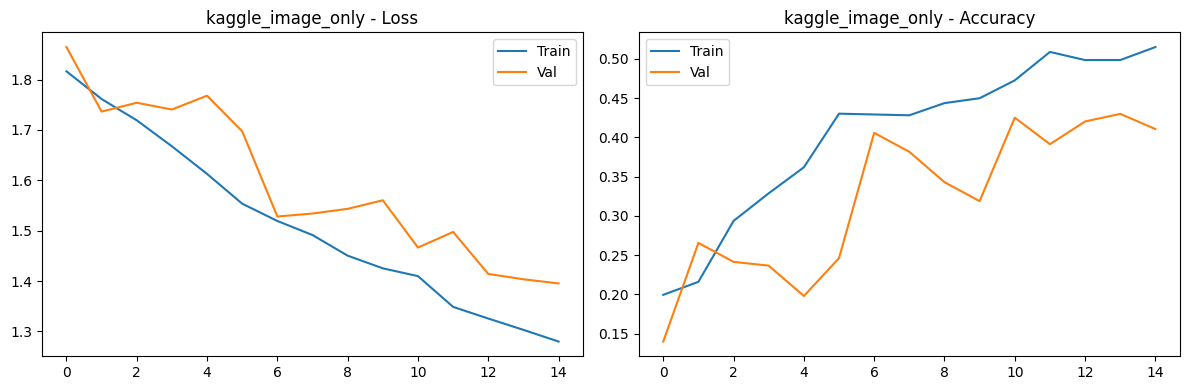

In [27]:
import matplotlib.pyplot as plt

def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(train_loss, label='Train'); axes[0].plot(val_loss, label='Val')
    axes[0].set_title(f'{title} - Loss'); axes[0].legend()
    axes[1].plot(train_acc, label='Train'); axes[1].plot(val_acc, label='Val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/curve_{title}.png')
    plt.show()

plot_curves(history_img['train_loss'], history_img['val_loss'], history_img['train_acc'], history_img['val_acc'], 'kaggle_image_only')

In [28]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

meta_model = MetaOnlyModel(meta_input_dim=META_DIM, num_classes=6).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

history_meta = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    history_meta['train_loss'].append(train_loss); history_meta['val_loss'].append(val_loss)
    history_meta['train_acc'].append(train_acc); history_meta['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/kaggle/working/best_meta_only.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.8490, Train acc: 0.1799 - Val loss: 1.8990, Val acc: 0.0145
  -> Saved new best model
Epoch 2/15 - Train loss: 1.8013, Train acc: 0.1965 - Val loss: 1.8924, Val acc: 0.0145
Epoch 3/15 - Train loss: 1.7854, Train acc: 0.2006 - Val loss: 1.8572, Val acc: 0.0145
Epoch 4/15 - Train loss: 1.7710, Train acc: 0.2006 - Val loss: 1.8676, Val acc: 0.0145
Epoch 5/15 - Train loss: 1.7705, Train acc: 0.2089 - Val loss: 1.8370, Val acc: 0.0145
Epoch 6/15 - Train loss: 1.7580, Train acc: 0.2461 - Val loss: 1.8079, Val acc: 0.0193
  -> Saved new best model
Epoch 7/15 - Train loss: 1.7679, Train acc: 0.2265 - Val loss: 1.7972, Val acc: 0.0290
  -> Saved new best model
Epoch 8/15 - Train loss: 1.7516, Train acc: 0.2358 - Val loss: 1.7858, Val acc: 0.0435
  -> Saved new best model
Epoch 9/15 - Train loss: 1.7397, Train acc: 0.2554 - Val loss: 1.7994, Val acc: 0.0242
Epoch 10/15 - Train loss: 1.7430, Train acc: 0.2492 - Val loss: 1.8013, Val acc: 0.0435
Epoch 11/15 - Train loss:

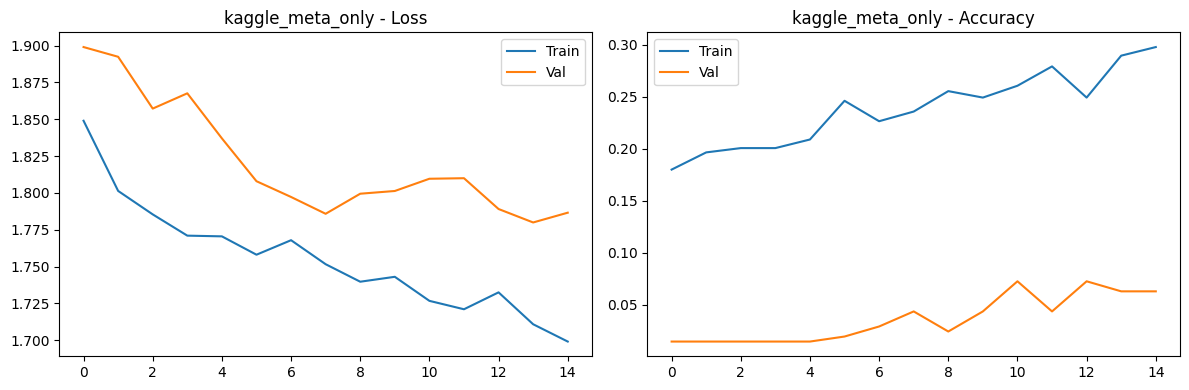

In [29]:
plot_curves(history_meta['train_loss'], history_meta['val_loss'], history_meta['train_acc'], history_meta['val_acc'], 'kaggle_meta_only')

In [30]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

metablock_model = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=6).to(device)
metablock_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_mb = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(20):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    history_mb['train_loss'].append(train_loss); history_mb['val_loss'].append(val_loss)
    history_mb['train_acc'].append(train_acc); history_mb['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/20 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/kaggle/working/best_metablock.pth')
        print("  -> Saved new best model")

Epoch 1/20 - Train loss: 1.7896, Train acc: 0.1903 - Val loss: 1.6616, Val acc: 0.5024
  -> Saved new best model
Epoch 2/20 - Train loss: 1.7317, Train acc: 0.2565 - Val loss: 1.7566, Val acc: 0.1063
Epoch 3/20 - Train loss: 1.6926, Train acc: 0.3020 - Val loss: 1.6864, Val acc: 0.2850
Epoch 4/20 - Train loss: 1.6269, Train acc: 0.3568 - Val loss: 1.6550, Val acc: 0.2754
Epoch 5/20 - Train loss: 1.5801, Train acc: 0.3754 - Val loss: 1.5268, Val acc: 0.4734
Epoch 6/20 - Train loss: 1.5238, Train acc: 0.4395 - Val loss: 1.6205, Val acc: 0.2174
Epoch 7/20 - Train loss: 1.4578, Train acc: 0.4478 - Val loss: 1.5463, Val acc: 0.2899
Epoch 8/20 - Train loss: 1.4088, Train acc: 0.4819 - Val loss: 1.4871, Val acc: 0.4396
Epoch 9/20 - Train loss: 1.3501, Train acc: 0.4984 - Val loss: 1.4871, Val acc: 0.2995
Epoch 10/20 - Train loss: 1.3346, Train acc: 0.5088 - Val loss: 1.4741, Val acc: 0.3671
Epoch 11/20 - Train loss: 1.2879, Train acc: 0.5264 - Val loss: 1.5229, Val acc: 0.2415
Epoch 12/20 - T

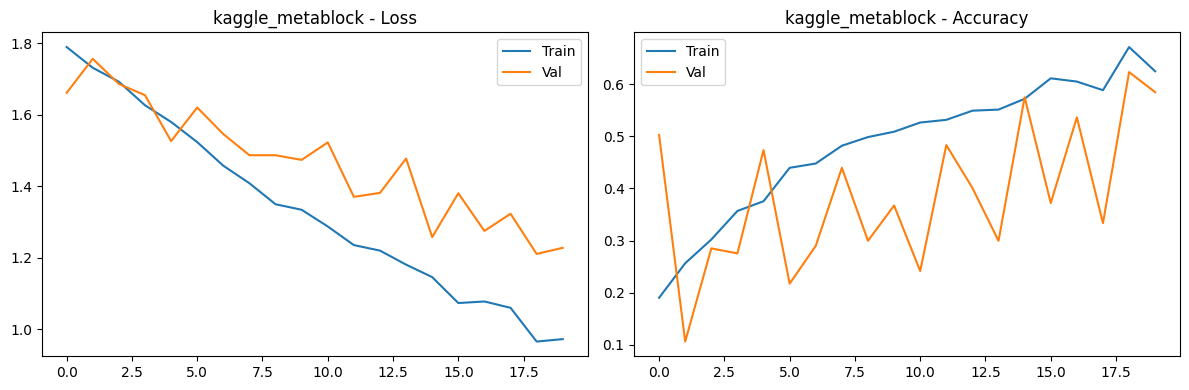

In [31]:
plot_curves(history_mb['train_loss'], history_mb['val_loss'], history_mb['train_acc'], history_mb['val_acc'], 'kaggle_metablock')

In [32]:
metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock.pth'))
test_loss, test_acc = evaluate(metablock_model, test_loader, criterion, device)
print(f"MetaBlock Test acc (seeded): {test_acc:.4f}")

MetaBlock Test acc (seeded): 0.5774


In [36]:
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import WeightedRandomSampler

# Fixed reference columns from the FULL dataset — guarantees consistent width across all 10 seeds
full_ref_columns = encode_metadata(df_clean, cat_cols, numeric_cols).columns
FIXED_META_DIM = len(full_ref_columns)
print("Fixed META_DIM for all seeds:", FIXED_META_DIM)

results_10runs_pad_v2 = []

for seed in range(1, 11):
    print(f"\n===== SEED {seed} (new split + new weights) =====")
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)

    sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    trainval_idx, test_idx = next(sgkf1.split(df_clean, df_clean['diagnostic'], groups=df_clean['patient_id']))
    trainval_df_s = df_clean.iloc[trainval_idx].reset_index(drop=True)
    test_df_s = df_clean.iloc[test_idx].reset_index(drop=True)

    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    train_idx, val_idx = next(sgkf2.split(trainval_df_s, trainval_df_s['diagnostic'], groups=trainval_df_s['patient_id']))
    train_df_s = trainval_df_s.iloc[train_idx].reset_index(drop=True)
    val_df_s = trainval_df_s.iloc[val_idx].reset_index(drop=True)

    train_meta_s = encode_metadata(train_df_s, cat_cols, numeric_cols, reference_columns=full_ref_columns)
    test_meta_s = encode_metadata(test_df_s, cat_cols, numeric_cols, reference_columns=full_ref_columns)

    le_s = LabelEncoder()
    le_s.fit(train_df_s['diagnostic'])
    train_labels_s = le_s.transform(train_df_s['diagnostic'])
    test_labels_s = le_s.transform(test_df_s['diagnostic'])

    train_dataset_s = SkinFusionDataset(train_df_s, train_meta_s, train_labels_s, image_folders, train_transform)
    test_dataset_s = SkinFusionDataset(test_df_s, test_meta_s, test_labels_s, image_folders, transform)

    class_sample_counts_s = np.array([sum(train_labels_s == i) for i in range(6)])
    class_sample_counts_s = np.where(class_sample_counts_s == 0, 1, class_sample_counts_s)
    sample_weights_s = 1.0 / class_sample_counts_s[train_labels_s]
    sampler_s = WeightedRandomSampler(sample_weights_s, num_samples=len(sample_weights_s), replacement=True)

    train_loader_s = DataLoader(train_dataset_s, batch_size=32, sampler=sampler_s, num_workers=2)
    test_loader_s = DataLoader(test_dataset_s, batch_size=32, shuffle=False, num_workers=2)

    class_weights_s = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels_s), y=train_labels_s), dtype=torch.float32).to(device)
    criterion_s = nn.CrossEntropyLoss(weight=class_weights_s)

    m = FusionModel(meta_input_dim=FIXED_META_DIM, num_classes=6).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(20):
        train_one_epoch(m, train_loader_s, criterion_s, opt, device)

    mb = MetaBlock(image_feat_dim=512, meta_input_dim=FIXED_META_DIM, num_classes=6).to(device)
    mb_opt = torch.optim.Adam(filter(lambda p: p.requires_grad, mb.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(20):
        train_one_epoch(mb, train_loader_s, criterion_s, mb_opt, device)

    adf = compute_ablation_importance(m, test_loader_s, device)
    adf['image_importance'] = adf['baseline_prob'] - adf['no_image_prob']
    adf['shapley_image'] = 0.5*(adf['no_meta_prob']-adf['none_prob']) + 0.5*(adf['baseline_prob']-adf['no_image_prob'])

    ig_scores = compute_ig_importance(m, test_loader_s, device)
    adf['ig_image'] = ig_scores

    gate_scores = compute_gate_importance(mb, test_loader_s, device)
    adf['gate_image'] = gate_scores

    rho_shap, _ = spearmanr(adf['image_importance'], adf['shapley_image'])
    rho_ig, _ = spearmanr(adf['image_importance'], adf['ig_image'])
    rho_gate, _ = spearmanr(adf['image_importance'], adf['gate_image'])

    _, fusion_test_acc = evaluate(m, test_loader_s, criterion_s, device)
    _, mb_test_acc = evaluate(mb, test_loader_s, criterion_s, device)

    results_10runs_pad_v2.append({
        'seed': seed, 'rho_shapley': rho_shap, 'rho_ig': rho_ig, 'rho_gate': rho_gate,
        'fusion_acc': fusion_test_acc, 'metablock_acc': mb_test_acc
    })
    print(f"rho_shapley={rho_shap:.3f}, rho_ig={rho_ig:.3f}, rho_gate={rho_gate:.3f}, fusion_acc={fusion_test_acc:.3f}, mb_acc={mb_test_acc:.3f}")

results_df_pad_v2 = pd.DataFrame(results_10runs_pad_v2)
print("\n===== SUMMARY (mean ± std across 10 different splits+seeds, PAD-UFES-20) =====")
print(results_df_pad_v2[['rho_shapley', 'rho_ig', 'rho_gate', 'fusion_acc', 'metablock_acc']].agg(['mean', 'std']))

results_df_pad_v2.to_csv('/kaggle/working/10run_results_pad_v2.csv', index=False)

Fixed META_DIM for all seeds: 72

===== SEED 1 (new split + new weights) =====
rho_shapley=0.953, rho_ig=0.397, rho_gate=-0.191, fusion_acc=0.131, mb_acc=0.115

===== SEED 2 (new split + new weights) =====
rho_shapley=0.977, rho_ig=0.179, rho_gate=-0.104, fusion_acc=0.111, mb_acc=0.143

===== SEED 3 (new split + new weights) =====
rho_shapley=0.959, rho_ig=0.092, rho_gate=-0.077, fusion_acc=0.050, mb_acc=0.039

===== SEED 4 (new split + new weights) =====
rho_shapley=0.939, rho_ig=0.118, rho_gate=0.008, fusion_acc=0.090, mb_acc=0.060

===== SEED 5 (new split + new weights) =====
rho_shapley=0.898, rho_ig=0.134, rho_gate=0.068, fusion_acc=0.044, mb_acc=0.056

===== SEED 6 (new split + new weights) =====
rho_shapley=0.928, rho_ig=0.031, rho_gate=0.041, fusion_acc=0.153, mb_acc=0.116

===== SEED 7 (new split + new weights) =====
rho_shapley=0.965, rho_ig=0.181, rho_gate=0.146, fusion_acc=0.127, mb_acc=0.122

===== SEED 8 (new split + new weights) =====
rho_shapley=0.964, rho_ig=0.296, rho